<a href="https://colab.research.google.com/github/hugueskz/ML_Model_Salaries/blob/main/Group_Project_Salaries_hkz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np                    # numbers and maths
import pandas as pd                   # tables (DataFrames)
import matplotlib.pyplot as plt       # charts

from sklearn.preprocessing import StandardScaler        # standardise: mean 0, standard deviation 1
from sklearn.decomposition import PCA                   # principal components analysis
from sklearn.linear_model import LinearRegression       # a linear regression
from sklearn.pipeline import make_pipeline              # chain steps into one model
from sklearn.model_selection import LeaveOneOut         # predict each row from all the others
from sklearn.model_selection import cross_val_predict   # make those out-of-sample predictions
from sklearn.metrics import r2_score                    # score predictions with R²
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

In [ ]:
# URL Github
url = "https://raw.githubusercontent.com/gaspardcostes/projet-salaire-IA-ML/refs/heads/main/ai_jobs_salaries_clean.csv"

In [ ]:
pd.read_csv(url)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71908,2020,SE,FT,Data Scientist,412000,USD,412000,US,100,US,L,Senior-level,Full-time,Remote,True,Data Scientist,"Mathematicians, actuaries and statisticians"
71909,2021,MI,FT,Principal Data Scientist,151000,USD,151000,US,100,US,L,Mid-level,Full-time,Remote,False,Data Scientist,"Mathematicians, actuaries and statisticians"
71910,2020,EN,FT,Data Scientist,105000,USD,105000,US,100,US,S,Entry-level,Full-time,Remote,False,Data Scientist,"Mathematicians, actuaries and statisticians"
71911,2020,EN,CT,Business Data Analyst,100000,USD,100000,US,100,US,L,Entry-level,Contract,Remote,False,Data Analyst,Business services and administration managers


In [ ]:
df = pd.read_csv(url)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71913 entries, 0 to 71912
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   work_year               71913 non-null  int64 
 1   experience_level        71913 non-null  object
 2   employment_type         71913 non-null  object
 3   job_title               71913 non-null  object
 4   salary                  71913 non-null  int64 
 5   salary_currency         71913 non-null  object
 6   salary_in_usd           71913 non-null  int64 
 7   employee_residence      71913 non-null  object
 8   remote_ratio            71913 non-null  int64 
 9   company_location        71913 non-null  object
 10  company_size            71913 non-null  object
 11  experience_level_label  71913 non-null  object
 12  employment_type_label   71913 non-null  object
 13  work_mode               71913 non-null  object
 14  salary_outlier_flag     71913 non-null  bool  
 15  ro

In [ ]:
df = df.drop(columns=["isco_group_hint"])

In [ ]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,71913.000000,7.191300e+04,71913.000000,71913.000000
mean,2024.425153,1.617102e+05,151161.252625,24.569271
std,0.721198,2.872868e+05,77329.594122,42.917779
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,9.640000e+04,96000.000000,0.000000
50%,2025.000000,1.397000e+05,138750.000000,0.000000
75%,2025.000000,1.922000e+05,190315.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


In [ ]:
print('missing per column:'); print(df.isna().sum())
print('\nduplicate rows:', df.duplicated().sum())

missing per column:
work_year                 0
experience_level          0
employment_type           0
job_title                 0
salary                    0
salary_currency           0
salary_in_usd             0
employee_residence        0
remote_ratio              0
company_location          0
company_size              0
experience_level_label    0
employment_type_label     0
work_mode                 0
salary_outlier_flag       0
role_family               0
dtype: int64

duplicate rows: 0


For Categorical target is work_mode

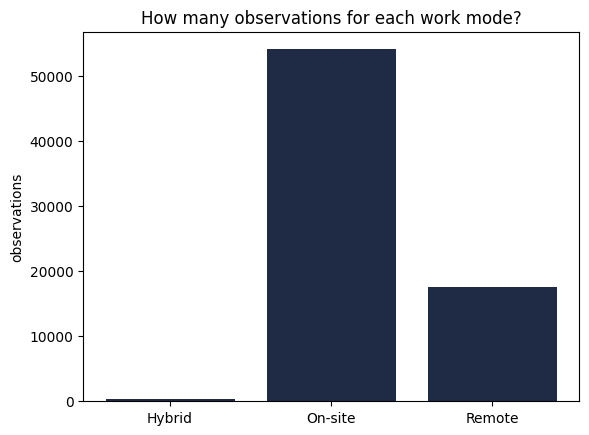

In [ ]:
counts = df['work_mode'].value_counts().sort_index()
plt.bar(counts.index, counts.values, color='#1F2A44')
plt.title('How many observations for each work mode?')
plt.ylabel('observations')
plt.show()

In [ ]:
print((df['work_mode'] == 'hybrid').sum())

0


In [ ]:
df['work_mode_binary'] = df['work_mode'].map({'Remote': 1, 'On-site': 0})
print(df.groupby('work_mode_binary')['remote_ratio'].mean())

work_mode_binary
0.0      0.0
1.0    100.0
Name: remote_ratio, dtype: float64


For Quantitative target is salary_in_usd

In [ ]:
print(df[['salary', 'salary_in_usd', 'salary_currency']].head())
print(df[['salary', 'salary_in_usd']].corr())

   salary  salary_in_usd salary_currency
0  348516         348516             USD
1  232344         232344             USD
2  145400         145400             USD
3   81600          81600             USD
4  160000         160000             USD
                 salary  salary_in_usd
salary         1.000000       0.224115
salary_in_usd  0.224115       1.000000


In [ ]:
print(df.groupby('salary_outlier_flag')['salary_in_usd'].mean())

salary_outlier_flag
False    144696.468122
True     409748.946978
Name: salary_in_usd, dtype: float64


In [ ]:
print(df.groupby('salary_outlier_flag')['salary_in_usd'].describe())

                       count           mean           std       min       25%  \
salary_outlier_flag                                                             
False                70159.0  144696.468122  64832.364871   15000.0   95000.0   
True                  1754.0  409748.946978  92242.103181  332000.0  350000.0   

                          50%       75%       max  
salary_outlier_flag                                
False                136700.0  185800.0  331640.0  
True                 376000.0  429415.0  800000.0  


Split the data (no more risk of overfitting)

In [ ]:
cat_features = ['experience_level', 'employment_type', 'company_size']
# Note : 'job_title' et 'company_location' are excluded for now. Risk of overfitting.

# 2. Correction of categorical target (to avoid the NaN error)
df['work_mode_encoded'] = df['work_mode'].map({'On-site': 0, 'Hybrid': 1, 'Remote': 2})

# --- SETUP FOR RÉGRESSION ---
features_reg = cat_features + ['remote_ratio']
X_reg = df[features_reg]
y_reg = df['salary_in_usd']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.25, random_state=42)

# --- SETUP FOR CLASSIFICATION  ---
features_classif = cat_features + ['salary_in_usd'] # remote_ratio excluded (data leakage)
X_class = df[features_classif]
y_class = df['work_mode_encoded']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_class, y_class, test_size=0.25, random_state=42)

In [ ]:
# Preprocessor 1 : For trees models (Random Forest, XGBoost)
# Trees don't need standardisation
preprocessor_tree = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), cat_features),
    remainder='passthrough'
)

# Preprocessor 2 : For linear model (Régression Linéaire, Régression Logistique)
# Standardisation of numerical columns
preprocessor_linear = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), cat_features),
    remainder=StandardScaler()
)

In [ ]:
# BASELINE RÉGRESSION (Always predict the salary mean)
baseline_reg = make_pipeline(preprocessor_tree, DummyRegressor(strategy='mean'))
baseline_reg.fit(Xr_train, yr_train)
yr_pred_base = baseline_reg.predict(Xr_train)
print(f"Erreur moyenne (MAE) de la Baseline Régression : {mean_absolute_error(yr_train, yr_pred_base):.0f} $")

# BASELINE CLASSIFICATION (Always predict the dominant class)
baseline_classif = make_pipeline(preprocessor_tree, DummyClassifier(strategy='most_frequent'))
baseline_classif.fit(Xc_train, yc_train)
yc_pred_base = baseline_classif.predict(Xc_train)
print(f"Précision de la Baseline Classification : {accuracy_score(yc_train, yc_pred_base):.2%}")

Erreur moyenne (MAE) de la Baseline Régression : 58567 $
Précision de la Baseline Classification : 75.19%


In [ ]:
# Regression
model_reg_linear = make_pipeline(preprocessor_linear, LinearRegression())
model_reg_rf = make_pipeline(preprocessor_tree, RandomForestRegressor(random_state=42, max_depth=10))
model_reg_xgb = make_pipeline(preprocessor_tree, XGBRegressor(random_state=42, max_depth=6, learning_rate=0.1))

# Cross-validation evaluation (5 blocs)
cv_linear = -cross_val_score(model_reg_linear, Xr_train, yr_train, cv=5, scoring='neg_mean_absolute_error')
cv_rf = -cross_val_score(model_reg_rf, Xr_train, yr_train, cv=5, scoring='neg_mean_absolute_error')
cv_xgb = -cross_val_score(model_reg_xgb, Xr_train, yr_train, cv=5, scoring='neg_mean_absolute_error')

print("\n--- SCORES DE VALIDATION CROISÉE (RÉGRESSION) ---")
print(f"Régression Linéaire : {cv_linear.mean():.0f} $")
print(f"Random Forest       : {cv_rf.mean():.0f} $")
print(f"XGBoost             : {cv_xgb.mean():.0f} $")


# Classification
model_classif_logistic = make_pipeline(preprocessor_linear, LogisticRegression(random_state=42, max_iter=1000))


model_classif_rf = make_pipeline(preprocessor_tree, RandomForestClassifier(random_state=42, max_depth=10))
model_classif_xgb = make_pipeline(preprocessor_tree, XGBClassifier(random_state=42, max_depth=6, learning_rate=0.1))

# Cross-validation evaluation (5 blocs) ---
cv_logistic = cross_val_score(model_classif_logistic, Xc_train, yc_train, cv=5, scoring='accuracy')
cv_classif_rf = cross_val_score(model_classif_rf, Xc_train, yc_train, cv=5, scoring='accuracy')
cv_classif_xgb = cross_val_score(model_classif_xgb, Xc_train, yc_train, cv=5, scoring='accuracy')


print("\n--- SCORES DE VALIDATION CROISÉE (CLASSIFICATION) ---")
print(f"Régression Logistique : {cv_logistic.mean():.2%}")
print(f"Random Forest         : {cv_classif_rf.mean():.2%}")
print(f"XGBoost               : {cv_classif_xgb.mean():.2%}")


--- SCORES DE VALIDATION CROISÉE (RÉGRESSION) ---
Régression Linéaire : 54312 $
Random Forest       : 54219 $
XGBoost             : 54217 $

--- SCORES DE VALIDATION CROISÉE (CLASSIFICATION) ---
Régression Logistique : 75.27%
Random Forest         : 75.36%
XGBoost               : 75.38%



Score Final sur le Test Set (MAE XGBoost) : 54094 $
Score Final Test Set (Classification RF) : 75.39%


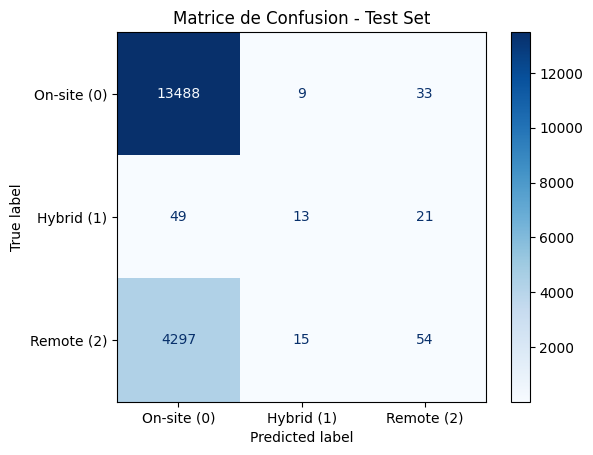

In [ ]:
# We take XGBoost as the best model for regression and train him on the train set
best_reg_model = model_reg_xgb
best_reg_model.fit(Xr_train, yr_train)

# Prediction on the test set
yr_test_pred = best_reg_model.predict(Xr_test)
print(f"\nScore Final sur le Test Set (MAE XGBoost) : {mean_absolute_error(yr_test, yr_test_pred):.0f} $")

# We take random forest for classication, training and drawing of the confusion matrix
best_classif_model = make_pipeline(preprocessor_tree, RandomForestClassifier(random_state=42, max_depth=10))
best_classif_model.fit(Xc_train, yc_train)
yc_test_pred = best_classif_model.predict(Xc_test)

print(f"Score Final Test Set (Classification RF) : {accuracy_score(yc_test, yc_test_pred):.2%}")
ConfusionMatrixDisplay.from_predictions(yc_test, yc_test_pred, display_labels=['On-site (0)', 'Hybrid (1)', 'Remote (2)'], cmap='Blues')
plt.title("Matrice de Confusion - Test Set")
plt.show()

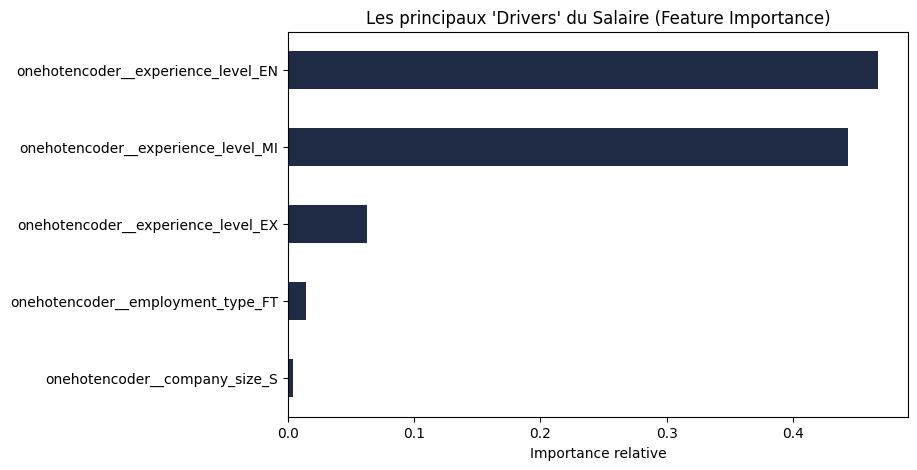

In [ ]:
encoded_cols = best_reg_model.named_steps['columntransformer'].get_feature_names_out()

# Importance of variables from XGBoost
importances = best_reg_model.named_steps['xgbregressor'].feature_importances_
feature_importances = pd.Series(importances, index=encoded_cols).sort_values(ascending=True)


plt.figure(figsize=(8, 5))
feature_importances.tail(5).plot(kind='barh', color='#1F2A44')
plt.title("Les principaux 'Drivers' du Salaire (Feature Importance)")
plt.xlabel("Importance relative")
plt.show()

## **2nd part : Going further, Improving the model**

In [ ]:
# --- 1. OUTLIER REMOVAL ON SALARY ---
Q1 = df['salary_in_usd'].quantile(0.25)
Q3 = df['salary_in_usd'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds (1.5 times the interquartile range)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the DataFrame to keep only realistic salaries
print(f"Rows before cleaning: {len(df)}")
df = df[(df['salary_in_usd'] >= lower_bound) & (df['salary_in_usd'] <= upper_bound)]
print(f"Rows after outlier removal: {len(df)}")

Rows before cleaning: 71913
Rows after outlier removal: 70159


In [ ]:
# --- 1. FEATURE ENGINEERING ---

# Geographic grouping: The US market pays differently than the rest of the world
df['location_grouped'] = df['company_location'].apply(lambda x: 'US' if x == 'US' else 'Outside_US')

# Job grouping: Keep the Top 5, the rest becomes "Other"
top_5_jobs = df['job_title'].value_counts().nlargest(5).index.tolist()
df['job_title_grouped'] = df['job_title'].apply(lambda x: x if x in top_5_jobs else 'Other')

# Ensure the categorical target is properly formatted (correction of the Hybrid error)
df['work_mode_encoded'] = df['work_mode'].map({'On-site': 0, 'Hybrid': 1, 'Remote': 2})

In [ ]:
# --- 2. NEW DATA SETUP ---

# Update variable lists with our newly created features
cat_features_adv = ['experience_level', 'employment_type', 'company_size', 'location_grouped', 'job_title_grouped']
num_features_adv = ['work_year']

# Preparation for Regression (Salary) - Inclusion of remote_ratio
features_reg_adv = cat_features_adv + num_features_adv + ['remote_ratio']
X_reg_adv = df[features_reg_adv]
y_reg_adv = df['salary_in_usd']
Xr_train_adv, Xr_test_adv, yr_train_adv, yr_test_adv = train_test_split(X_reg_adv, y_reg_adv, test_size=0.25, random_state=42)

# Preparation for Classification (Work mode) - Exclusion of remote_ratio, addition of salary
features_classif_adv = cat_features_adv + num_features_adv + ['salary_in_usd']
X_class_adv = df[features_classif_adv]
y_class_adv = df['work_mode_encoded']
Xc_train_adv, Xc_test_adv, yc_train_adv, yc_test_adv = train_test_split(X_class_adv, y_class_adv, test_size=0.25, random_state=42)

In [ ]:
# --- 3. INDEPENDENT PREPROCESSORS AND NEW MODELS ---

# A preprocessor dedicated to regression
preprocessor_reg_adv = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), cat_features_adv),
    remainder='passthrough'
)

# A preprocessor dedicated to classification
preprocessor_classif_adv = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), cat_features_adv),
    remainder='passthrough'
)

# Improved Regression Model
model_reg_adv = make_pipeline(
    preprocessor_reg_adv,
    XGBRegressor(random_state=42, max_depth=6, learning_rate=0.1)
)

# Improved Classification Model (WITH class rebalancing)
model_classif_adv = make_pipeline(
    preprocessor_classif_adv,
    RandomForestClassifier(random_state=42, max_depth=10, class_weight='balanced')
)

# Final training (each on its own data)
model_reg_adv.fit(Xr_train_adv, yr_train_adv)
model_classif_adv.fit(Xc_train_adv, yc_train_adv)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['experience_level',
                                                   'employment_type',
                                                   'company_size',
                                                   'location_grouped',
                                                   'job_title_grouped'])])),
                ('randomforestclassifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        random_state=42))])

New MAE (XGBoost Regression) : 45307 $
New Accuracy (RF Classification) : 57.09%


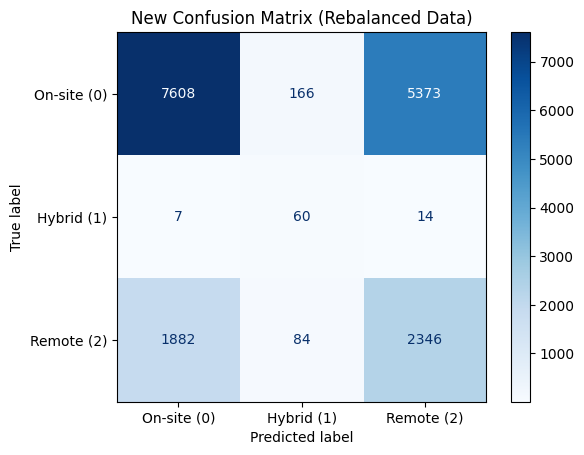

In [ ]:
# --- 4. IMPROVED PERFORMANCE EVALUATION ---

# Evaluation of the new Salary model
yr_test_pred_adv = model_reg_adv.predict(Xr_test_adv)
print(f"New MAE (XGBoost Regression) : {mean_absolute_error(yr_test_adv, yr_test_pred_adv):.0f} $")

# Evaluation of the new Classification model
yc_test_pred_adv = model_classif_adv.predict(Xc_test_adv)
print(f"New Accuracy (RF Classification) : {accuracy_score(yc_test_adv, yc_test_pred_adv):.2%}")

# Displaying the corrected matrix
ConfusionMatrixDisplay.from_predictions(yc_test_adv, yc_test_pred_adv, display_labels=['On-site (0)', 'Hybrid (1)', 'Remote (2)'], cmap='Blues')
plt.title("New Confusion Matrix (Rebalanced Data)")
plt.show()